
# Comparación UG vs RG para \(p=-\rho-A\rho^\nu\)

Este notebook genera, para cada intervalo de \(\nu\), cuatro gráficos:

\[
\rho(t), \qquad a(t), \qquad H(t), \qquad \dot H(t),
\]

comparando:

- **Gravedad unimodular (UG)** con difusión \(Q=\alpha\rho\): líneas continuas.
- **Relatividad general (RG)**: líneas punteadas.

## Unidades físicas usadas

Para mantener consistencia dimensional y, al mismo tiempo, conservar la forma de las soluciones empleadas en el proyecto, se trabaja primero con variables adimensionales normalizadas por \(H_0\) y por la densidad crítica actual,

\[
\rho_{c,0}=\frac{3H_0^2}{8\pi G}.
\]

Se define

\[
R\equiv \frac{\rho}{\rho_{c,0}},\qquad
\tau\equiv H_0(t-t_0),\qquad
E\equiv \frac{H}{H_0},
\]

y el parámetro adimensional

\[
\bar A \equiv A\,\rho_{c,0}^{\,\nu-1}.
\]

Los gráficos se convierten finalmente a:

- \(t\): **Gyr**
- \(\rho\): **kg m\(^{-3}\)**
- \(a(t)\): **adimensional**
- \(H\): **km s\(^{-1}\) Mpc\(^{-1}\)**
- \(\dot H\): **Gyr\(^{-2}\)**

> La normalización del factor de escala es \(a(t_0)=1\).  
> En cosmología, \(a(t)\) es adimensional.


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# Constantes físicas y parámetros globales
# ------------------------------------------------------------
G_SI = 6.67430e-11               # m^3 kg^-1 s^-2
MPC_M = 3.0856775814913673e22    # m
GYR_S = 365.25 * 24 * 3600 * 1e9 # s

H0_km_s_Mpc = 70.0
H0_SI = H0_km_s_Mpc * 1000.0 / MPC_M
H0_Gyr = H0_SI * GYR_S

# Tiempo de Hubble
tH_Gyr = 1.0 / H0_Gyr

# Densidad crítica actual
rho_c0 = 3.0 * H0_SI**2 / (8.0 * np.pi * G_SI)

print(f"H0 = {H0_km_s_Mpc:.1f} km s^-1 Mpc^-1")
print(f"H0^-1 = {tH_Gyr:.3f} Gyr")
print(f"rho_c,0 = {rho_c0:.4e} kg m^-3")


H0 = 70.0 km s^-1 Mpc^-1
H0^-1 = 13.968 Gyr
rho_c,0 = 9.2039e-27 kg m^-3



## Ecuaciones empleadas

Para el fluido fantasma

\[
p=-\rho-A\rho^\nu,
\]

y la función de difusión unimodular

\[
Q=\alpha\rho,
\]

la ecuación de continuidad modificada es

\[
\dot\rho+\dot Q+3H(\rho+p)=0.
\]

En las variables normalizadas del notebook,

\[
\frac{dR}{d\tau}
=
\frac{3\bar A}{\sqrt{1+\alpha}}
R^{\nu+1/2},
\]

mientras que en RG se recupera el límite \(\alpha=0\).

Para \(\nu\neq 1/2\),

\[
R(\tau)=
\left[
R_0^{(1-2\nu)/2}
+
\frac{3\bar A}{2\sqrt{1+\alpha}}
(1-2\nu)\tau
\right]^{\frac{2}{1-2\nu}}.
\]

El factor de escala se obtiene de

\[
R(a)=
\left[
R_0^{1-\nu}
+
\frac{3\bar A(1-\nu)}{1+\alpha}\ln\!\left(\frac{a}{a_0}\right)
\right]^{1/(1-\nu)},
\]

es decir,

\[
a(R)=a_0\exp\!\left[
\frac{1+\alpha}{3\bar A(1-\nu)}
\left(R^{1-\nu}-R_0^{1-\nu}\right)
\right],
\qquad \nu\neq1.
\]

Además,

\[
E_{\rm UG}=\sqrt{(1+\alpha)R},
\qquad
E_{\rm RG}=\sqrt{R},
\]

y

\[
\frac{dE}{d\tau}
=
\frac{3\bar A}{2}R^\nu.
\]

Por tanto,

\[
\dot H = H_0^2\,\frac{dE}{d\tau}.
\]

El caso \(\nu=1/2\) y el caso \(\nu=1\) se excluyen aquí porque requieren expresiones especiales y no forman parte de los intervalos usados en esta comparación.


In [2]:

# ------------------------------------------------------------
# Parámetros del modelo
# ------------------------------------------------------------
Abar = 0.6      # Abar = A * rho_c0^(nu-1), parámetro adimensional
alpha_UG = 0.3  # Q = alpha*rho

R0 = 1.0        # rho(t0)/rho_c0
a0 = 1.0        # normalización cosmológica

# Valores de nu por intervalo.
# Se dejan como diccionario para que puedas modificarlos fácilmente.
NU_GROUPS = {
    r"$\nu<0$": [-1.0, -0.75, -0.50, -0.25],
    r"$\nu=0$": [0.0],
    r"$0<\nu<1/2$": [0.10, 0.20, 0.30, 0.40],
    r"$1/2<\nu<1$": [0.60, 0.70, 0.80, 0.90],
    r"$\nu>1$": [1.10, 1.20, 1.30, 1.40],
}

# Máximo valor de densidad normalizada que se representa.
# Evita evaluar exactamente en la singularidad.
R_PLOT_MAX = 1e15
NPTS = 1800


In [3]:

# ------------------------------------------------------------
# Soluciones analíticas
# ------------------------------------------------------------
def rho_bar_of_tau(tau, nu, Abar=Abar, alpha=0.0, R0=R0):
    """R(tau) = rho/rho_c0 para nu != 1/2."""
    if np.isclose(nu, 0.5):
        raise ValueError("nu = 1/2 requiere una solución especial.")
    if alpha <= -1:
        raise ValueError("Se requiere 1 + alpha > 0.")

    power0 = (1.0 - 2.0*nu) / 2.0
    base = R0**power0 + (
        3.0*Abar*(1.0 - 2.0*nu) / (2.0*np.sqrt(1.0 + alpha))
    ) * tau

    exponent = 2.0 / (1.0 - 2.0*nu)

    R = np.full_like(np.asarray(tau, dtype=float), np.nan, dtype=float)
    mask = base > 0.0
    R[mask] = base[mask]**exponent
    return R


def a_of_rho_bar(R, nu, Abar=Abar, alpha=0.0, R0=R0, a0=a0):
    """Factor de escala a(R), normalizado a(t0)=a0, para nu != 1."""
    if np.isclose(nu, 1.0):
        raise ValueError("nu = 1 requiere una solución especial.")

    expo = (
        (1.0 + alpha)
        * (R**(1.0 - nu) - R0**(1.0 - nu))
        / (3.0*Abar*(1.0 - nu))
    )

    # Evita overflow numérico en exp; para los gráficos basta con cortar antes.
    expo = np.clip(expo, -700, 700)
    return a0 * np.exp(expo)


def E_of_rho_bar(R, alpha=0.0):
    """E = H/H0."""
    return np.sqrt((1.0 + alpha) * R)


def dE_dtau_of_rho_bar(R, nu, Abar=Abar):
    """dE/dtau. Para este modelo, la dependencia explícita en alpha se cancela."""
    return 1.5 * Abar * R**nu


def tau_to_gyr(tau):
    return tau * tH_Gyr


def rho_bar_to_si(R):
    return R * rho_c0


def E_to_H_km_s_Mpc(E):
    return E * H0_km_s_Mpc


def dE_dtau_to_Hdot_gyr2(dE_dtau):
    # H = H0 E, tau = H0 t  => dH/dt = H0^2 dE/dtau
    # al expresar H0 en Gyr^-1, el resultado queda en Gyr^-2.
    return (H0_Gyr**2) * dE_dtau


def tau_singularity(nu, Abar=Abar, alpha=0.0, R0=R0):
    """Tiempo adimensional de divergencia de R para nu > 1/2."""
    if nu <= 0.5:
        return np.inf
    return (
        2.0*np.sqrt(1.0 + alpha)
        * R0**((1.0 - 2.0*nu)/2.0)
        / (3.0*Abar*(2.0*nu - 1.0))
    )


def tau_for_R_target(R_target, nu, Abar=Abar, alpha=0.0, R0=R0):
    """Tiempo adimensional en que se alcanza una densidad R_target."""
    if np.isclose(nu, 0.5):
        raise ValueError("nu = 1/2 requiere tratamiento especial.")

    power0 = (1.0 - 2.0*nu) / 2.0
    return (
        (R_target**power0 - R0**power0)
        * 2.0*np.sqrt(1.0 + alpha)
        / (3.0*Abar*(1.0 - 2.0*nu))
    )



## Criterio de corte de las curvas

Para los casos con singularidad futura se evita evaluar exactamente en \(t_s\). En su lugar, cada curva se detiene cuando

\[
R=\frac{\rho}{\rho_{c,0}}=10^{15}.
\]

Esto reproduce visualmente el crecimiento divergente sin introducir `inf` o `nan` por evaluar exactamente en la singularidad.

Para \(\nu\leq 1/2\), donde la divergencia no ocurre a tiempo finito, se usa una ventana temporal común elegida automáticamente a partir del intervalo.


In [4]:

# ------------------------------------------------------------
# Construcción automática de la ventana temporal
# ------------------------------------------------------------
def choose_tau_max(nus, alpha_ug=alpha_UG, R_target=R_PLOT_MAX):
    nus = list(nus)

    if any(nu > 0.5 for nu in nus):
        # Para singularidades finitas: mostrar hasta que la curva UG más tardía
        # alcance R_target.
        vals = []
        for nu in nus:
            for alpha in (0.0, alpha_ug):
                vals.append(tau_for_R_target(R_target, nu, alpha=alpha))
        return 1.02 * max(vals)

    # Para intervalos no singulares en tiempo finito:
    # ventanas elegidas para mostrar claramente la evolución tardía.
    if all(nu < 0 for nu in nus):
        return 12.0
    if len(nus) == 1 and np.isclose(nus[0], 0.0):
        return 10.0
    return 10.0


def finite_curve(tau, nu, alpha, R_target=R_PLOT_MAX):
    R = rho_bar_of_tau(tau, nu, alpha=alpha)
    mask = np.isfinite(R) & (R > 0) & (R <= R_target)

    # a(t) puede crecer enormemente; lo calculamos sólo en el dominio físico.
    Rm = R[mask]
    tm = tau[mask]

    a = a_of_rho_bar(Rm, nu, alpha=alpha)
    E = E_of_rho_bar(Rm, alpha=alpha)
    dE = dE_dtau_of_rho_bar(Rm, nu)

    return tm, Rm, a, E, dE


In [5]:

# ------------------------------------------------------------
# Función de graficación: 4 paneles por intervalo de nu
# ------------------------------------------------------------
def plot_interval(title, nus, alpha_ug=alpha_UG, save=False, outdir="figuras_unidades"):
    tau_max = choose_tau_max(nus, alpha_ug=alpha_ug)
    tau = np.linspace(0.0, tau_max, NPTS)

    fig, axs = plt.subplots(2, 2, figsize=(15, 8.5))
    ax_rho, ax_a, ax_H, ax_Hdot = axs.flat

    # El ciclo de colores de matplotlib asigna un color por nu.
    # Para mantener exactamente el mismo color en UG y RG, guardamos el color.
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    for i, nu in enumerate(nus):
        color = colors[i % len(colors)]

        # UG: línea continua
        t_u, R_u, a_u, E_u, dE_u = finite_curve(tau, nu, alpha_ug)
        t_u_gyr = tau_to_gyr(t_u)

        ax_rho.plot(
            t_u_gyr, rho_bar_to_si(R_u),
            "-", lw=2.1, color=color, label=fr"$\nu={nu:g}$"
        )
        ax_a.plot(t_u_gyr, a_u, "-", lw=2.1, color=color)
        ax_H.plot(t_u_gyr, E_to_H_km_s_Mpc(E_u), "-", lw=2.1, color=color)
        ax_Hdot.plot(t_u_gyr, dE_dtau_to_Hdot_gyr2(dE_u), "-", lw=2.1, color=color)

        # RG: línea punteada
        t_g, R_g, a_g, E_g, dE_g = finite_curve(tau, nu, 0.0)
        t_g_gyr = tau_to_gyr(t_g)

        ax_rho.plot(t_g_gyr, rho_bar_to_si(R_g), "--", lw=2.0, color=color)
        ax_a.plot(t_g_gyr, a_g, "--", lw=2.0, color=color)
        ax_H.plot(t_g_gyr, E_to_H_km_s_Mpc(E_g), "--", lw=2.0, color=color)
        ax_Hdot.plot(t_g_gyr, dE_dtau_to_Hdot_gyr2(dE_g), "--", lw=2.0, color=color)

    # Títulos
    ax_rho.set_title("Densidad de energía")
    ax_a.set_title("Factor de escala")
    ax_H.set_title("Parámetro de Hubble")
    ax_Hdot.set_title("Derivada del parámetro de Hubble")

    # Ejes con unidades físicas
    for ax in axs.flat:
        ax.set_xlabel(r"$t-t_0$ [Gyr]")
        ax.grid(True, alpha=0.28)

    ax_rho.set_ylabel(r"$\rho(t)$ [kg m$^{-3}$]")
    ax_a.set_ylabel(r"$a(t)$ [adimensional]")
    ax_H.set_ylabel(r"$H(t)$ [km s$^{-1}$ Mpc$^{-1}$]")
    ax_Hdot.set_ylabel(r"$\dot H(t)$ [Gyr$^{-2}$]")

    # Escalas logarítmicas donde el rango dinámico es grande
    ax_rho.set_yscale("log")
    ax_H.set_yscale("log")
    ax_Hdot.set_yscale("log")

    # Para a(t), log ayuda sobre todo en Big Rip; en el resto sigue siendo legible.
    ax_a.set_yscale("log")

    # Leyenda de nu
    leg_nu = ax_rho.legend(title=r"Valores de $\nu$", loc="upper left", fontsize=9)

    # Leyenda separada para el tipo de gravedad
    from matplotlib.lines import Line2D
    style_handles = [
        Line2D([0], [0], color="black", lw=2.2, ls="-",
               label=fr"UG ($\alpha={alpha_ug:g}$)"),
        Line2D([0], [0], color="black", lw=2.2, ls="--", label="RG"),
    ]
    ax_rho.add_artist(leg_nu)
    ax_rho.legend(handles=style_handles, title="Marco", loc="lower right", fontsize=9)

    fig.suptitle(
        fr"Comparación UG vs RG: {title}  "
        fr"($\bar A={Abar:g}$, $\alpha={alpha_ug:g}$, "
        fr"$H_0={H0_km_s_Mpc:g}$ km s$^{{-1}}$ Mpc$^{{-1}}$)",
        fontsize=15
    )

    fig.tight_layout(rect=[0, 0, 1, 0.955])

    if save:
        outdir = Path(outdir)
        outdir.mkdir(parents=True, exist_ok=True)
        safe = (
            title.replace("$", "")
                 .replace("\\", "")
                 .replace("/", "_")
                 .replace("<", "lt")
                 .replace(">", "gt")
                 .replace(" ", "_")
        )
        fig.savefig(outdir / f"UG_vs_RG_{safe}.png", dpi=220, bbox_inches="tight")

    plt.show()


In [11]:
# ------------------------------------------------------------
# Función de graficación: 4 paneles por intervalo de nu
# CON UNIDADES FÍSICAS
# ------------------------------------------------------------

def plot_interval(
    title,
    nus,
    alpha_ug=alpha_UG,
    save=False,
    outdir="figuras_unidades",
    H0_km_s_Mpc=70.0
):

    # --------------------------------------------------------
    # Constantes y conversiones de unidades
    # --------------------------------------------------------

    G = 6.67430e-11                    # m^3 kg^-1 s^-2
    c = 299792458.0                    # m s^-1
    Mpc_m = 3.085677581491367e22       # m
    Gyr_s = 365.25 * 24 * 3600 * 1e9  # s

    # H0 en s^-1
    H0_SI = H0_km_s_Mpc * 1000.0 / Mpc_m

    # H0 en Gyr^-1
    H0_Gyr = H0_SI * Gyr_s

    # Densidad crítica actual:
    # rho_c0 = 3 H0^2 / (8 pi G)
    # Esta expresión entrega densidad de masa equivalente [kg m^-3]
    rho_c0 = 3.0 * H0_SI**2 / (8.0 * np.pi * G)

    # Si queremos llamarla estrictamente "densidad de energía":
    # epsilon_c0 = rho_c0 * c^2 [J m^-3]
    epsilon_c0 = rho_c0 * c**2


    # --------------------------------------------------------
    # Ventana temporal del gráfico
    # --------------------------------------------------------

    tau_max = choose_tau_max(nus, alpha_ug=alpha_ug)

    # tau = H0 (t - t0)
    tau = np.linspace(0.0, tau_max, NPTS)


    # --------------------------------------------------------
    # Figura
    # --------------------------------------------------------

    fig, axs = plt.subplots(2, 2, figsize=(15, 8.5))

    ax_rho, ax_a, ax_H, ax_Hdot = axs.flat


    # Colores: mismo color para UG y RG con el mismo nu
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]


    # --------------------------------------------------------
    # Curvas
    # --------------------------------------------------------

    for i, nu in enumerate(nus):

        color = colors[i % len(colors)]


        # ====================================================
        # UG: línea continua
        # ====================================================

        t_u, R_u, a_u, E_u, dE_u = finite_curve(
            tau,
            nu,
            alpha_ug
        )

        # ----------------------------------------------------
        # Conversión a unidades físicas
        #
        # tau = H0(t-t0)
        # R   = rho/rho_c0
        # E   = H/H0
        # dE/dtau = Hdot/H0^2
        # ----------------------------------------------------

        # Tiempo [Gyr]
        t_u_gyr = t_u / H0_Gyr

        # Densidad de energía [J m^-3]
        rho_u_phys = R_u * epsilon_c0

        # Hubble [km s^-1 Mpc^-1]
        H_u_phys = E_u * H0_km_s_Mpc

        # Hdot [Gyr^-2]
        Hdot_u_phys = dE_u * H0_Gyr**2


        ax_rho.plot(
            t_u_gyr,
            rho_u_phys,
            "-",
            lw=2.1,
            color=color,
            label=fr"$\nu={nu:g}$"
        )

        ax_a.plot(
            t_u_gyr,
            a_u,
            "-",
            lw=2.1,
            color=color
        )

        ax_H.plot(
            t_u_gyr,
            H_u_phys,
            "-",
            lw=2.1,
            color=color
        )

        ax_Hdot.plot(
            t_u_gyr,
            Hdot_u_phys,
            "-",
            lw=2.1,
            color=color
        )


        # ====================================================
        # RG: línea punteada
        # ====================================================

        t_g, R_g, a_g, E_g, dE_g = finite_curve(
            tau,
            nu,
            0.0
        )

        # Tiempo [Gyr]
        t_g_gyr = t_g / H0_Gyr

        # Densidad de energía [J m^-3]
        rho_g_phys = R_g * epsilon_c0

        # Hubble [km s^-1 Mpc^-1]
        H_g_phys = E_g * H0_km_s_Mpc

        # Hdot [Gyr^-2]
        Hdot_g_phys = dE_g * H0_Gyr**2


        ax_rho.plot(
            t_g_gyr,
            rho_g_phys,
            "--",
            lw=2.0,
            color=color
        )

        ax_a.plot(
            t_g_gyr,
            a_g,
            "--",
            lw=2.0,
            color=color
        )

        ax_H.plot(
            t_g_gyr,
            H_g_phys,
            "--",
            lw=2.0,
            color=color
        )

        ax_Hdot.plot(
            t_g_gyr,
            Hdot_g_phys,
            "--",
            lw=2.0,
            color=color
        )


    # --------------------------------------------------------
    # Títulos
    # --------------------------------------------------------

    ax_rho.set_title("Densidad de energía", fontsize=13)

    ax_a.set_title("Factor de escala", fontsize=13)

    ax_H.set_title("Parámetro de Hubble", fontsize=13)

    ax_Hdot.set_title(
        "Derivada del parámetro de Hubble",
        fontsize=13
    )


    # --------------------------------------------------------
    # Eje temporal
    # --------------------------------------------------------

    for ax in axs.flat:

        ax.set_xlabel(
            r"$t-t_0\;[\mathrm{Gyr}]$",
            fontsize=11
        )

        ax.grid(
            True,
            alpha=0.28
        )


    # --------------------------------------------------------
    # Ejes verticales con unidades físicas
    # --------------------------------------------------------

    ax_rho.set_ylabel(
        r"$\rho(t)\;[\mathrm{J\,m^{-3}}]$",
        fontsize=11
    )

    ax_a.set_ylabel(
        r"$a(t)$",
        fontsize=11
    )

    ax_H.set_ylabel(
        r"$H(t)\;[\mathrm{km\,s^{-1}\,Mpc^{-1}}]$",
        fontsize=11
    )

    ax_Hdot.set_ylabel(
        r"$\dot{H}(t)\;[\mathrm{Gyr^{-2}}]$",
        fontsize=11
    )


    # --------------------------------------------------------
    # Escalas logarítmicas
    # --------------------------------------------------------

    ax_rho.set_yscale("log")

    ax_a.set_yscale("log")

    ax_H.set_yscale("log")

    ax_Hdot.set_yscale("log")


    # --------------------------------------------------------
    # Leyenda: valores de nu
    # --------------------------------------------------------

    leg_nu = ax_rho.legend(
        title=r"Valores de $\nu$",
        loc="upper left",
        fontsize=9
    )


    # --------------------------------------------------------
    # Leyenda: UG vs RG
    # --------------------------------------------------------

    from matplotlib.lines import Line2D

    style_handles = [

        Line2D(
            [0],
            [0],
            color="black",
            lw=2.2,
            ls="-",
            label=fr"UG ($\alpha={alpha_ug:g}$)"
        ),

        Line2D(
            [0],
            [0],
            color="black",
            lw=2.2,
            ls="--",
            label="RG"
        ),
    ]


    ax_rho.add_artist(leg_nu)

    ax_rho.legend(
        handles=style_handles,
        title="Marco",
        loc="lower right",
        fontsize=9
    )


    # --------------------------------------------------------
    # Título general
    # --------------------------------------------------------

    fig.suptitle(
        fr"Comparación UG vs RG: {title}"
        + "\n"
        + fr"$H_0={H0_km_s_Mpc:g}\ "
          r"\mathrm{km\,s^{-1}\,Mpc^{-1}}$",
        fontsize=15
    )


    fig.tight_layout(
        rect=[0, 0, 1, 0.94]
    )


    # --------------------------------------------------------
    # Guardar figura
    # --------------------------------------------------------

    if save:

        outdir = Path(outdir)

        outdir.mkdir(
            parents=True,
            exist_ok=True
        )

        safe = (
            title.replace("$", "")
                 .replace("\\", "")
                 .replace("/", "_")
                 .replace("<", "lt")
                 .replace(">", "gt")
                 .replace(" ", "_")
        )

        fig.savefig(
            outdir / f"UG_vs_RG_{safe}.png",
            dpi=220,
            bbox_inches="tight"
        )


    plt.show()

## 1. Intervalo \(\nu<0\)

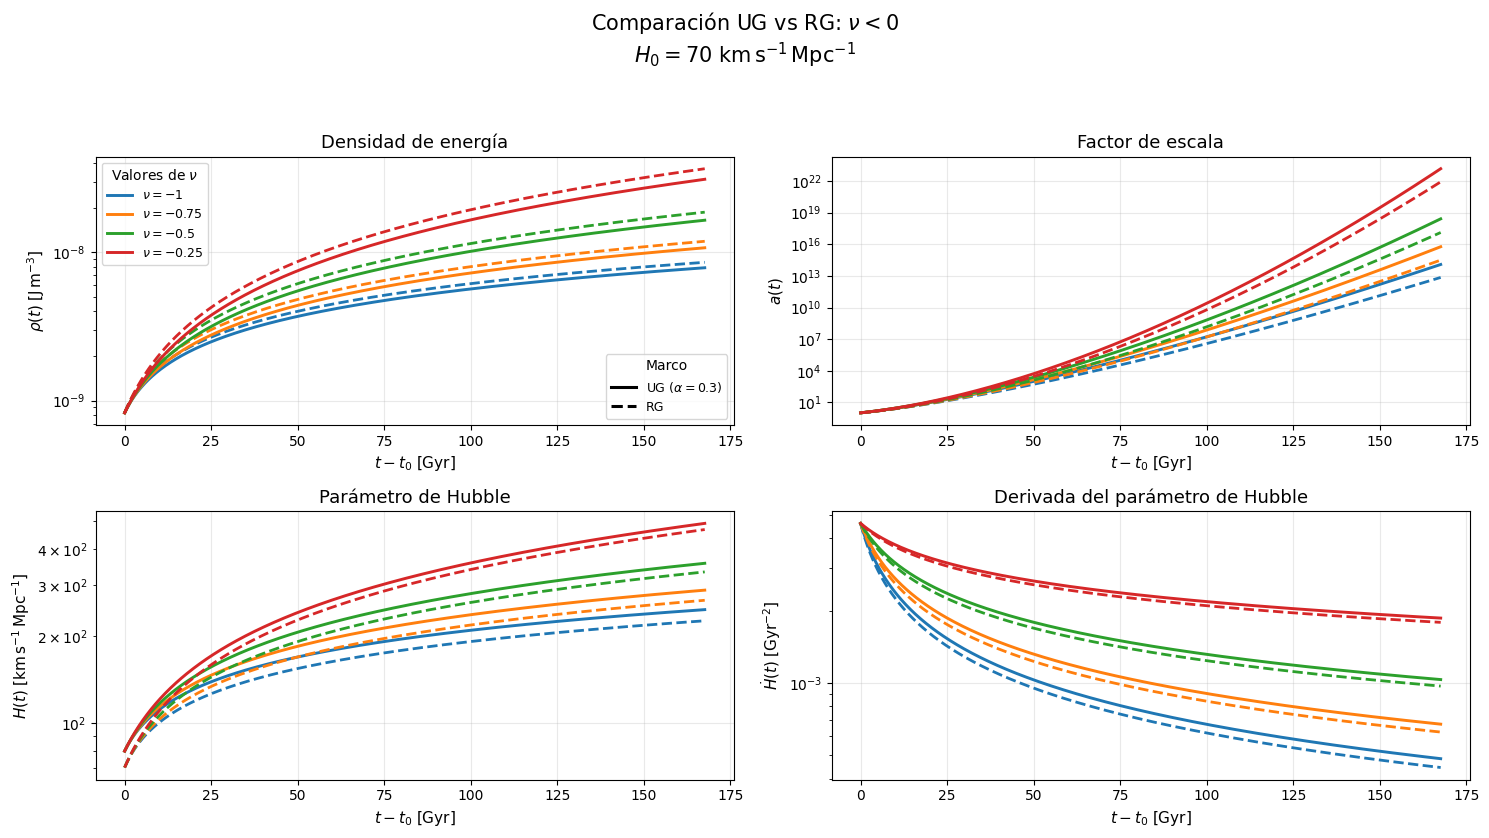

In [12]:
plot_interval(r"$\nu<0$", NU_GROUPS[r"$\nu<0$"])

## 2. Caso \(\nu=0\)

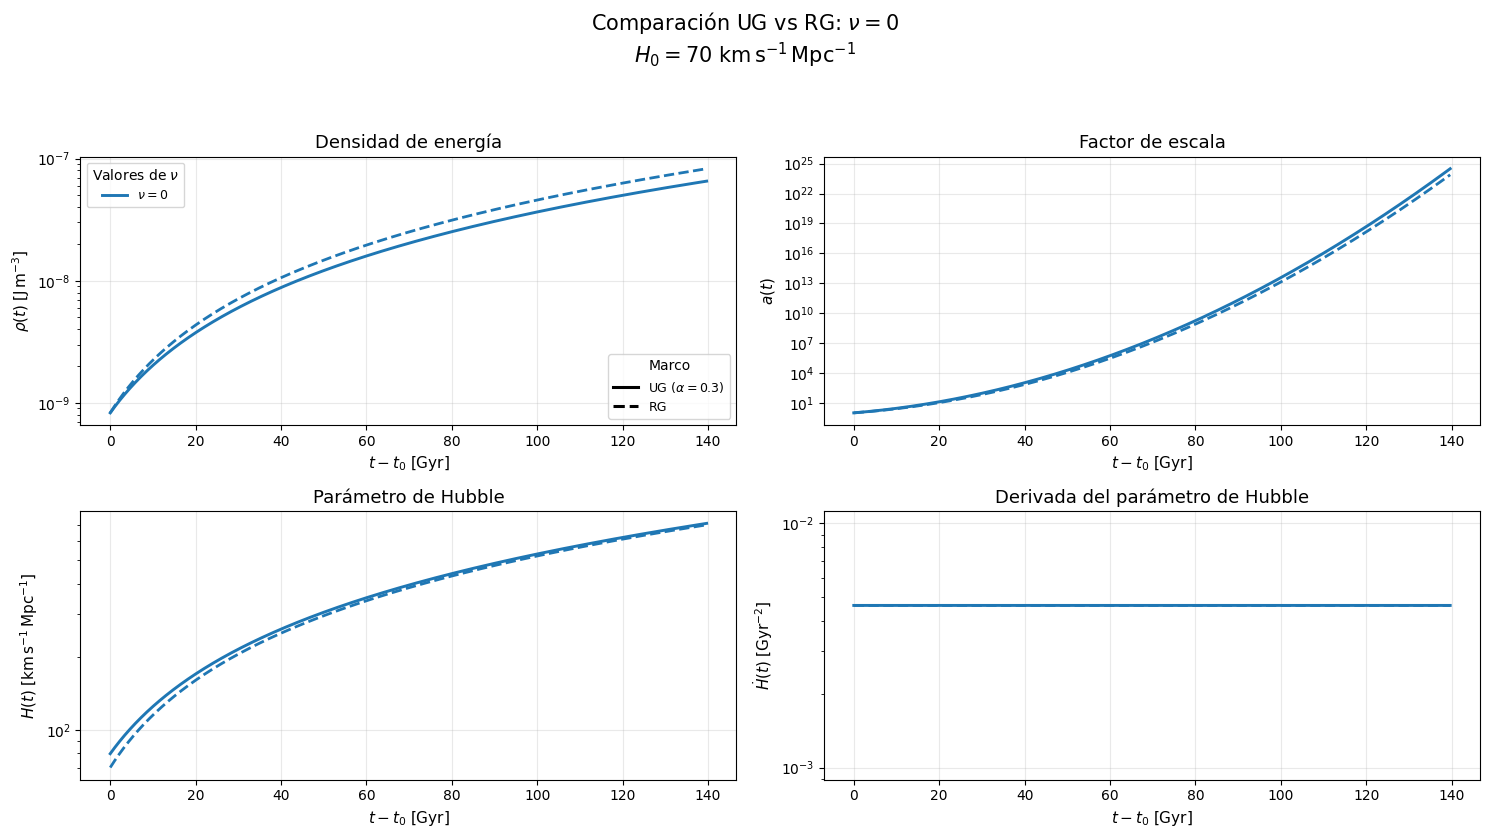

In [13]:
plot_interval(r"$\nu=0$", NU_GROUPS[r"$\nu=0$"])

## 3. Intervalo \(0<\nu<1/2\)

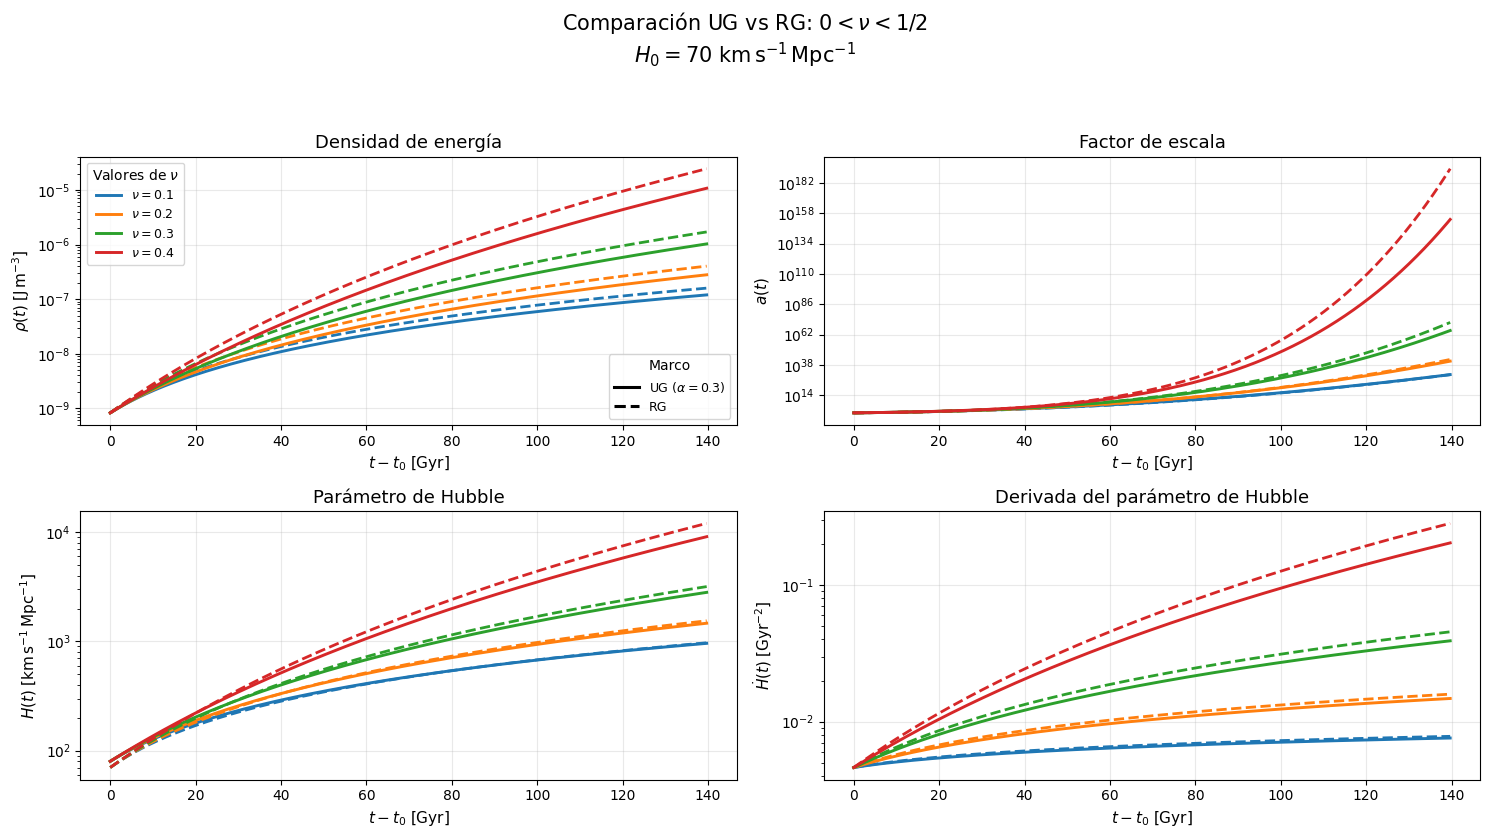

In [14]:
plot_interval(r"$0<\nu<1/2$", NU_GROUPS[r"$0<\nu<1/2$"])

## 4. Intervalo \(1/2<\nu<1\): Big Rip

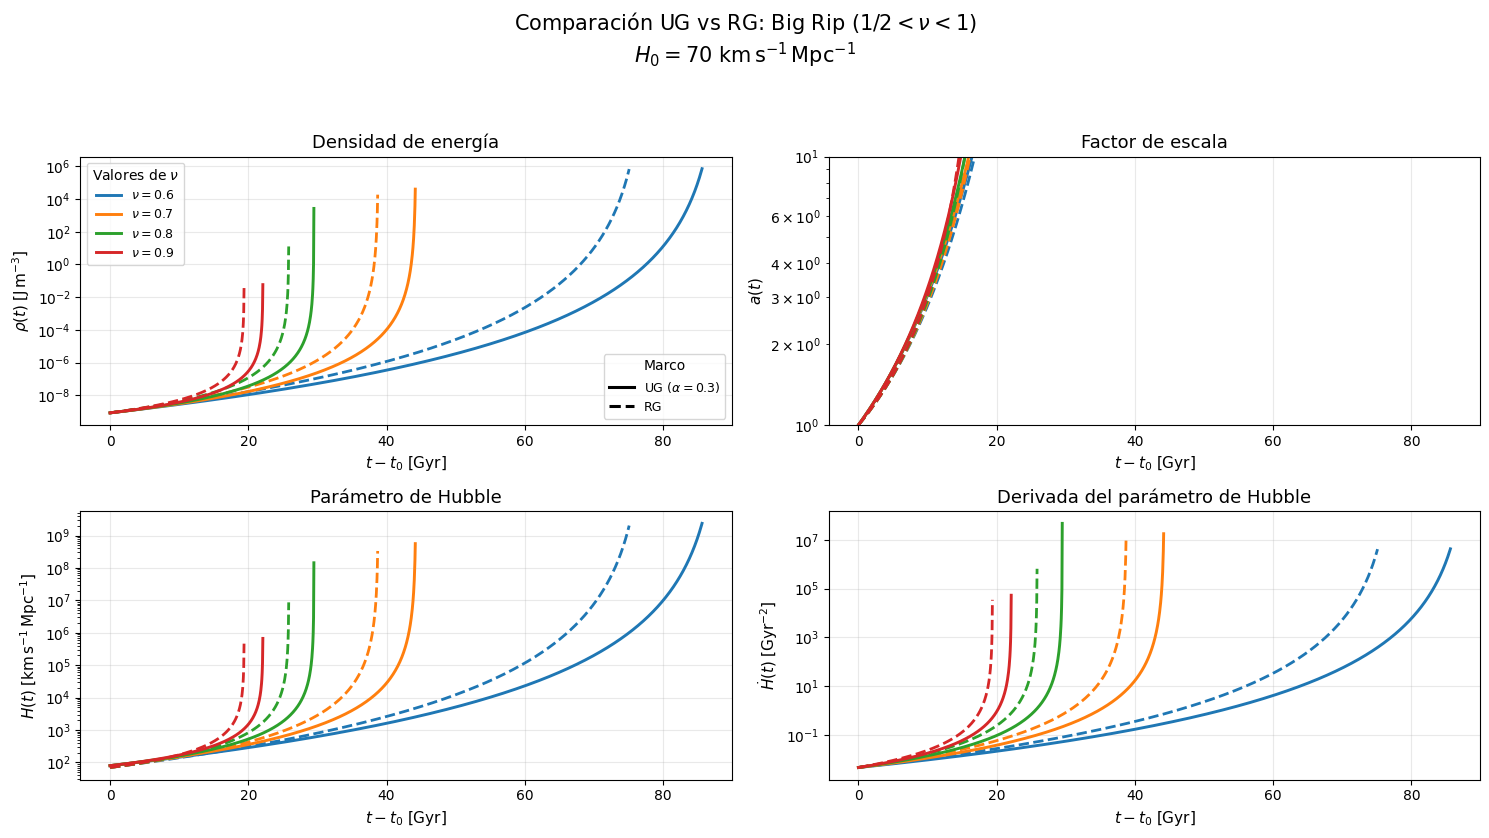

In [15]:
plot_interval(r"Big Rip ($1/2<\nu<1$)", NU_GROUPS[r"$1/2<\nu<1$"])

## 5. Intervalo \(\nu>1\): singularidad Tipo III

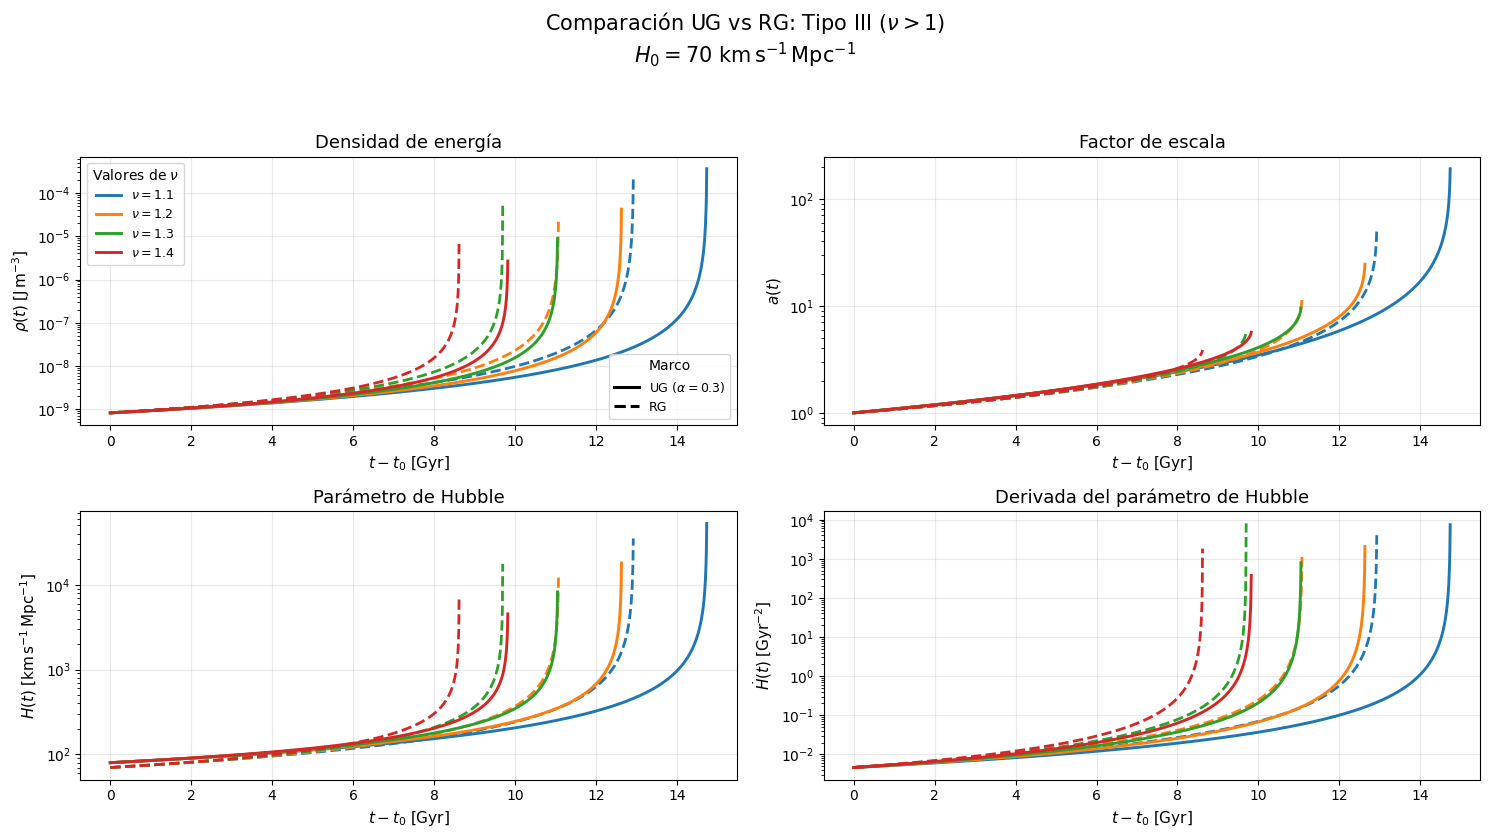

In [16]:
plot_interval(r"Tipo III ($\nu>1$)", NU_GROUPS[r"$\nu>1$"])


## Tiempos de singularidad para \(\nu>1/2\)

Para \(\nu>1/2\), la densidad diverge a tiempo finito. Con la normalización usada,

\[
\tau_s^{\rm RG}
=
\frac{2R_0^{(1-2\nu)/2}}
{3\bar A(2\nu-1)},
\]

y para UG,

\[
\tau_s^{\rm UG}
=
\sqrt{1+\alpha}\,
\tau_s^{\rm RG}.
\]

En unidades físicas,

\[
t_s-t_0=\frac{\tau_s}{H_0}.
\]

Por lo tanto, para \(\alpha>0\), la difusión retrasa la singularidad por el factor \(\sqrt{1+\alpha}\), sin cambiar su clasificación.


In [ ]:

# Tabla rápida de tiempos de singularidad en Gyr
rows = []

for interval_name in [r"$1/2<\nu<1$", r"$\nu>1$"]:
    for nu in NU_GROUPS[interval_name]:
        ts_rg = tau_singularity(nu, alpha=0.0) * tH_Gyr
        ts_ug = tau_singularity(nu, alpha=alpha_UG) * tH_Gyr
        rows.append((nu, ts_rg, ts_ug, ts_ug/ts_rg))

print(f"{'nu':>6} | {'t_s RG [Gyr]':>14} | {'t_s UG [Gyr]':>14} | {'UG/RG':>8}")
print("-"*55)
for nu, ts_rg, ts_ug, ratio in rows:
    print(f"{nu:6.2f} | {ts_rg:14.3f} | {ts_ug:14.3f} | {ratio:8.4f}")



## Guardar todas las figuras

Ejecuta esta celda si quieres exportar automáticamente los cinco conjuntos de gráficos en PNG.


In [ ]:

for title, nus in NU_GROUPS.items():
    plot_interval(title, nus, save=True)

print("Figuras guardadas en ./figuras_unidades/")



## Nota sobre \(A\) y sus unidades

La ecuación de estado física es

\[
p=-\rho-A\rho^\nu.
\]

Por consistencia dimensional,

\[
[A]=[\rho]^{\,1-\nu}.
\]

Por ello, cuando se comparan distintos valores de \(\nu\), **no es correcto interpretar un mismo número de \(A\) como la misma magnitud dimensional en SI**. En este notebook se fija el parámetro normalizado

\[
\bar A=A\rho_{c,0}^{\,\nu-1},
\]

que sí es adimensional y puede mantenerse constante entre curvas de distintos \(\nu\).

Esto permite añadir unidades físicas a \(\rho\), \(t\), \(H\) y \(\dot H\) sin romper la consistencia dimensional del modelo.
